# Model A: Custom CNN

Binary classification of real and AI-generated images
using a Custom Convolutional Neural Network.

Training environment: Google Colab
Dataset: Defactify Image Dataset
Framework: TensorFlow / Keras

In [ ]:
!pip -q install datasets huggingface_hub

In [ ]:
import os
import json
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image as PILImage
from datasets import load_dataset
from huggingface_hub import HfApi

In [ ]:
# GitHub repository
REPO_URL = (
    "https://github.com/Michaelatj/"
    "AI-Generated-Image-Classification-using-CNN.git"
)

REPO_DIR = Path(
    "/content/AI-Generated-Image-Classification-using-CNN"
)

# Clone repository if not available
if not REPO_DIR.exists():

    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

os.chdir(REPO_DIR)

# Sync with latest GitHub main branch
status = subprocess.check_output(
    ["git", "status", "--porcelain"],
    text=True
)

if status.strip():
    raise RuntimeError(
        "Repository contains local changes. "
        "Check git status before syncing."
    )

subprocess.run(
    ["git", "pull", "--rebase", "origin", "main"],
    check=True
)

# Project directories
ARTIFACT_DIR = REPO_DIR / "artifacts"
SPLIT_DIR = ARTIFACT_DIR / "splits"
CONFIG_DIR = ARTIFACT_DIR / "configs"
MODEL_DIR = ARTIFACT_DIR / "models"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Repository:", REPO_DIR)
print("Models directory:", MODEL_DIR)

Repository: /content/AI-Generated-Image-Classification-using-CNN
Models directory: /content/AI-Generated-Image-Classification-using-CNN/artifacts/models


In [ ]:
# TensorFlow configuration
SEED = 42

tf.keras.utils.set_random_seed(SEED)

# GPU configuration
gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(
            gpu,
            True
        )
    except RuntimeError as error:
        print(error)

print("TensorFlow:", tf.__version__)
print("Available GPU:", gpus)

# Check available Colab storage
total, used, free = shutil.disk_usage("/content")

print(f"Free storage: {free / (1024**3):.2f} GB")

TensorFlow: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Free storage: 112.51 GB


## Dataset Loading

Load the prepared CSV manifests and original images
from the Hugging Face Defactify Image Dataset.

Target:
- 0 = Real
- 1 = AI-Generated

The test split is reserved for final evaluation.

In [ ]:
TRAIN_CSV = SPLIT_DIR / "train.csv"
VAL_CSV = SPLIT_DIR / "validation.csv"
TEST_CSV = SPLIT_DIR / "test.csv"

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

# Sort to make image retrieval and prediction ordering consistent
train_df = train_df.sort_values(
    ["source_split", "row_idx"]
).reset_index(drop=True)

val_df = val_df.sort_values(
    ["source_split", "row_idx"]
).reset_index(drop=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (42018, 10)
Validation: (8994, 10)
Test: (44988, 10)


,image_id,source_split,row_idx,caption_group_id,caption,label_a,label_a_name,label_b,label_b_name,assigned_split
0,test_000004,test,4,9a17853ba3721cbc,The large winged bird is looking for some prey.,1,AI-Generated,5,Midjourney v6,train
1,test_000005,test,5,b0272b8a7bc5f1e1,This motorcycle is parked on the side of the g...,1,AI-Generated,2,Stable Diffusion XL (SDXL),train
2,test_000007,test,7,12257d367927c842,Shears and knives are in a cutting block.,1,AI-Generated,3,Stable Diffusion 3,train
3,test_000010,test,10,97c0fe59e2006ee2,A white passenger train traveling down train t...,1,AI-Generated,2,Stable Diffusion XL (SDXL),train
4,test_000011,test,11,6a60b1b0599562ca,a street light is hanging on a pole,1,AI-Generated,3,Stable Diffusion 3,train


In [ ]:
DATASET_ID = (
    "Rajarshi-Roy-research/Defactify_Image_Dataset"
)

HF_CACHE_DIR = "/content/huggingface_cache"

# Pin the dataset revision for reproducibility
HF_REVISION = HfApi().dataset_info(
    DATASET_ID
).sha

print("Dataset revision:", HF_REVISION)

HF_DATASETS = {}

# Only load the splits needed for training
required_splits = sorted(
    set(train_df["source_split"]).union(
        set(val_df["source_split"])
    )
)

for split_name in required_splits:

    print(f"\nLoading {split_name}...")

    HF_DATASETS[split_name] = load_dataset(
        DATASET_ID,
        split=split_name,
        revision=HF_REVISION,
        cache_dir=HF_CACHE_DIR
    )

    print(
        f"{split_name}: "
        f"{len(HF_DATASETS[split_name]):,} images"
    )

Dataset revision: 1c3b714c9691eb6dd11c2c1e92eab1ac29584fa0

Loading test...


README.md:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (30 outputs left out)

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

test: 45,000 images

Loading train...
train: 42,000 images

Loading validation...
validation: 9,000 images


In [ ]:
# Find overlapping caption groups
overlap_groups = (
    set(train_df["caption_group_id"].dropna())
    &
    set(val_df["caption_group_id"].dropna())
)

print("Total overlapping groups:", len(overlap_groups))

# Inspect overlapping groups
overlap_details = []

for group_id in sorted(overlap_groups):

    train_group = train_df[
        train_df["caption_group_id"] == group_id
    ]

    val_group = val_df[
        val_df["caption_group_id"] == group_id
    ]

    overlap_details.append({

        "caption_group_id": group_id,

        "train_rows": len(train_group),

        "validation_rows": len(val_group),

        "train_images": train_group["image_id"].tolist(),

        "validation_images": val_group["image_id"].tolist(),

        "caption": train_group["caption"].iloc[0]

    })

overlap_report = pd.DataFrame(overlap_details)

display(overlap_report)

Total overlapping groups: 0


""


In [ ]:
# Display first 3 overlapping groups

for group_id in sorted(overlap_groups)[:3]:

    print(f"\nCaption Group: {group_id}")

    train_group = train_df[
        train_df["caption_group_id"] == group_id
    ].copy()

    val_group = val_df[
        val_df["caption_group_id"] == group_id
    ].copy()

    train_group["dataset_split"] = "Train"
    val_group["dataset_split"] = "Validation"

    combined = pd.concat([
        train_group,
        val_group
    ])

    display(
        combined[[
            "image_id",
            "dataset_split",
            "caption_group_id",
            "label_a",
            "label_b",
            "caption"
        ]]
    )

In [ ]:
split_groups = {
    "train": set(train_df["caption_group_id"].dropna()),
    "validation": set(val_df["caption_group_id"].dropna()),
    "test": set(test_df["caption_group_id"].dropna())
}

print(
    "Train - Validation:",
    len(split_groups["train"] & split_groups["validation"])
)

print(
    "Train - Test:",
    len(split_groups["train"] & split_groups["test"])
)

print(
    "Validation - Test:",
    len(split_groups["validation"] & split_groups["test"])
)

Train - Validation: 0
Train - Test: 0
Validation - Test: 0


In [ ]:
def normalize_caption(text):
    return " ".join(
        str(text).strip().split()
    ).casefold()


required_columns = [
    "image_id",
    "source_split",
    "row_idx",
    "caption",
    "label_a",
    "label_b"
]

for name, df in [
    ("train", train_df),
    ("validation", val_df)
]:

    assert set(required_columns).issubset(df.columns)

    assert df["image_id"].is_unique

    assert not df[
        ["source_split", "row_idx", "caption", "label_a", "label_b"]
    ].isnull().any().any()

    assert df[["source_split", "row_idx"]].duplicated().sum() == 0

    assert set(df["label_a"].unique()).issubset({0, 1})


def validate_mapping(df, split_name):

    for source_split, group in df.groupby(
        "source_split",
        sort=False
    ):

        hf_dataset = HF_DATASETS[source_split]

        indices = group["row_idx"].astype(int).tolist()

        if min(indices) < 0 or max(indices) >= len(hf_dataset):
            raise IndexError(
                f"Invalid row_idx in {split_name}"
            )

        # Select original Hugging Face rows
        # without accessing the image column
        selected = hf_dataset.select(indices)

        actual_labels_a = np.asarray(
            selected["Label_A"]
        )

        actual_labels_b = np.asarray(
            selected["Label_B"]
        )

        expected_labels_a = group["label_a"].to_numpy()
        expected_labels_b = group["label_b"].to_numpy()

        assert np.array_equal(
            actual_labels_a,
            expected_labels_a
        ), f"Label_A mismatch: {split_name}"

        assert np.array_equal(
            actual_labels_b,
            expected_labels_b
        ), f"Label_B mismatch: {split_name}"

        actual_captions = [
            normalize_caption(x)
            for x in selected["Caption"]
        ]

        expected_captions = [
            normalize_caption(x)
            for x in group["caption"]
        ]

        assert actual_captions == expected_captions, (
            f"Caption mismatch: {split_name}"
        )

    print(
        f"{split_name}: image mapping verified!"
    )


validate_mapping(train_df, "train")
validate_mapping(val_df, "validation")

# Check caption group leakage
if "caption_group_id" in train_df.columns:

    train_groups = set(train_df["caption_group_id"].dropna())
    val_groups = set(val_df["caption_group_id"].dropna())

    overlap = train_groups & val_groups

    assert len(overlap) == 0, (
        f"Caption group leakage detected: {len(overlap)} groups"
    )

    print("No caption group leakage detected.")

train: image mapping verified!
validation: image mapping verified!
No caption group leakage detected.


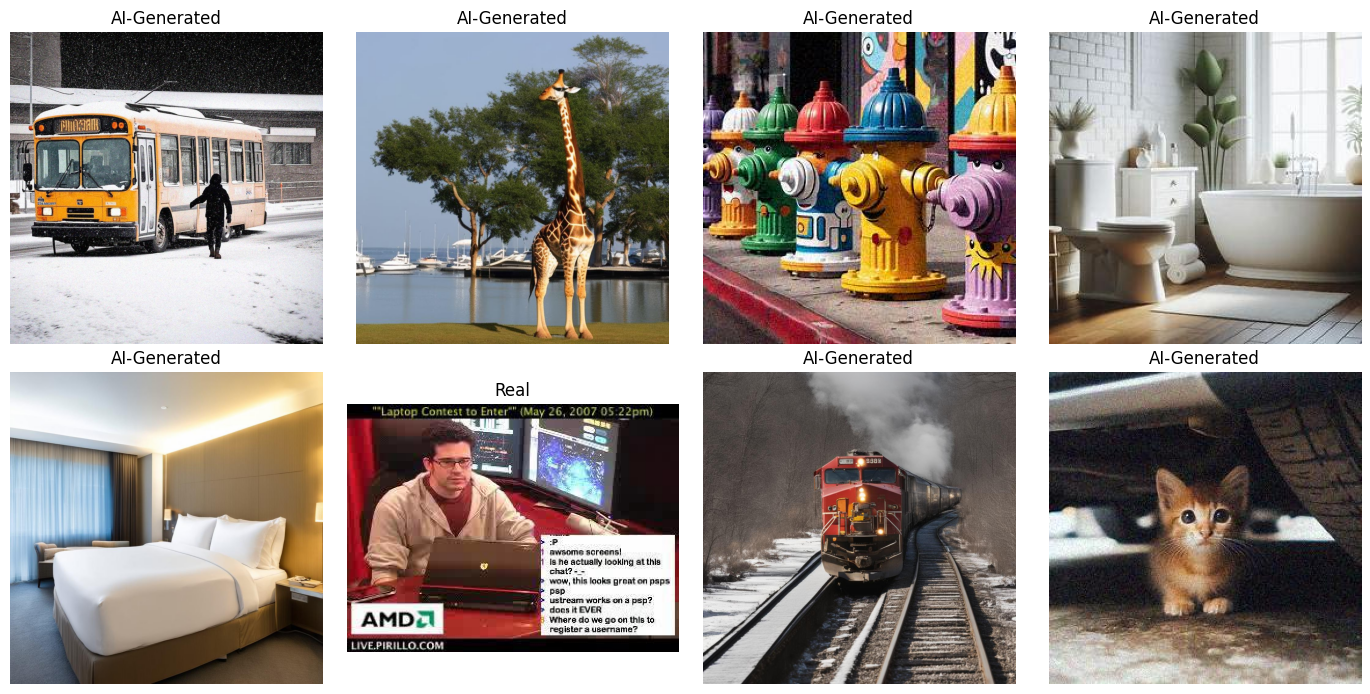

In [ ]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

sample_rows = train_df.sample(
    n=8,
    random_state=SEED
)

for ax, (_, row) in zip(
    axes.flatten(),
    sample_rows.iterrows()
):

    sample = HF_DATASETS[
        row["source_split"]
    ][int(row["row_idx"])]

    image = sample["Image"].convert("RGB")

    ax.imshow(image)

    label_name = (
        "Real"
        if row["label_a"] == 0
        else "AI-Generated"
    )

    ax.set_title(label_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Image Preprocessing and Data Pipeline

Retrieve images using source_split and row_idx.

Preprocessing:
- RGB conversion.
- Resize to 224 × 224.
- Convert to uint8 image tensors.
- Normalize pixel values inside the CNN.

Use tf.data for batching, shuffling, and prefetching.

In [ ]:
IMAGE_SIZE = 224
IMAGE_SHAPE = (224, 224, 3)

BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

# Calculate class weights from training data
class_counts = (
    train_df["label_a"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

if (class_counts == 0).any():
    raise ValueError("A training class is missing!")

total_samples = len(train_df)

class_weights = {
    label: total_samples / (
        2 * class_counts[label]
    )
    for label in [0, 1]
}

print("Class distribution:")
print(class_counts)

print("\nClass weights:")
print(class_weights)


def image_generator(df, training=False):

    for row in df.itertuples(index=False):

        # Retrieve original image
        sample = HF_DATASETS[
            row.source_split
        ][int(row.row_idx)]

        image = sample["Image"]

        if image is None:
            raise ValueError(
                f"Missing image: {row.image_id}"
            )

        # Convert to RGB and resize
        image = image.convert("RGB")

        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=PILImage.Resampling.BILINEAR
        )

        # Convert to NumPy array
        image_array = np.asarray(
            image,
            dtype=np.uint8
        )

        # Binary label
        label = np.array(
            [int(row.label_a)],
            dtype=np.float32
        )

        # Apply class weighting only to training data
        sample_weight = np.float32(
            class_weights[int(row.label_a)]
            if training else 1.0
        )

        yield image_array, label, sample_weight

Class distribution:
label_a
0     7003
1    35015
Name: count, dtype: int64

Class weights:
{0: np.float64(3.0), 1: np.float64(0.6)}


In [ ]:
OUTPUT_SIGNATURE = (

    tf.TensorSpec(
        shape=IMAGE_SHAPE,
        dtype=tf.uint8
    ),

    tf.TensorSpec(
        shape=(1,),
        dtype=tf.float32
    ),

    tf.TensorSpec(
        shape=(),
        dtype=tf.float32
    )
)


def create_tf_dataset(df, training=False):

    dataset = tf.data.Dataset.from_generator(
        lambda: image_generator(
            df,
            training=training
        ),
        output_signature=OUTPUT_SIGNATURE
    )

    # Verify expected number of samples
    dataset = dataset.apply(
        tf.data.experimental.assert_cardinality(
            len(df)
        )
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=512,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset


train_dataset = create_tf_dataset(
    train_df,
    training=True
)

val_dataset = create_tf_dataset(
    val_df,
    training=False
)

print("Train and validation pipelines created!")

Train and validation pipelines created!


Image shape: (16, 224, 224, 3)
Label shape: (16, 1)
Sample weight shape: (16,)
Image dtype: <dtype: 'uint8'>
Label dtype: <dtype: 'float32'>


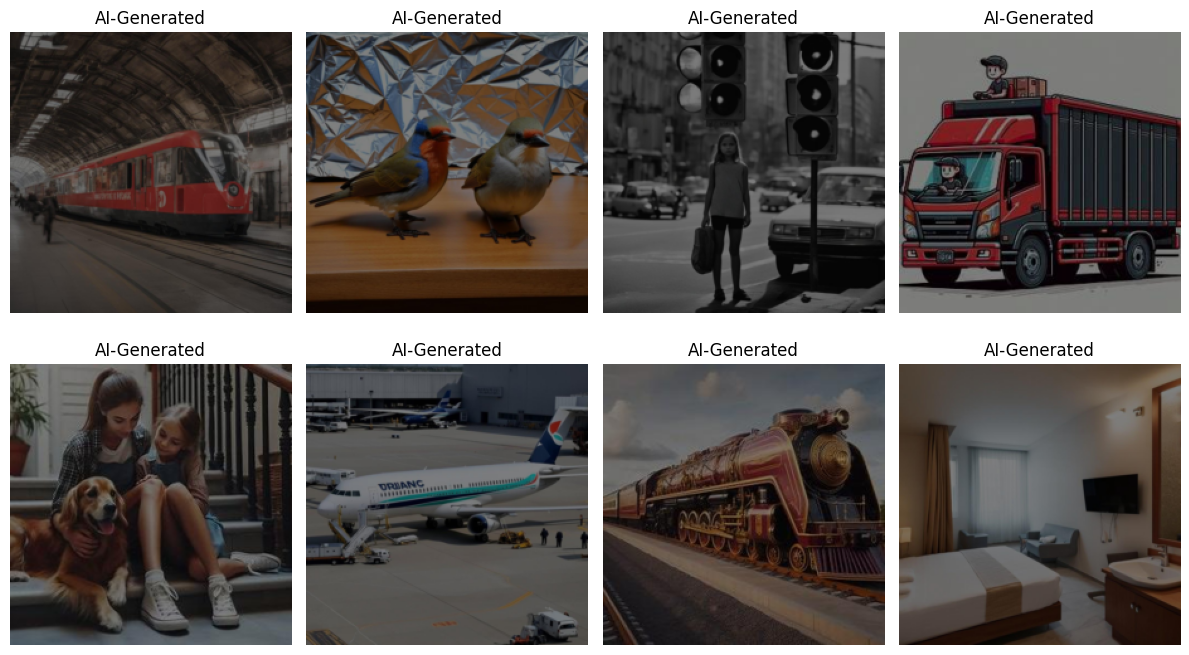

In [ ]:
images, labels, sample_weights = next(
    iter(train_dataset)
)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Sample weight shape:", sample_weights.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

# Display training samples
plt.figure(figsize=(12, 7))

for i in range(min(8, len(images))):

    plt.subplot(2, 4, i + 1)

    plt.imshow(
        images[i].numpy()
    )

    label = int(
        labels[i][0].numpy()
    )

    plt.title(
        "Real" if label == 0 else "AI-Generated"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## Custom CNN Architecture

Build a CNN from scratch for binary image classification.

Architecture:
- Input: 224 × 224 × 3
- Three convolution blocks: 32, 64, 128 filters
- Batch Normalization
- ReLU activation
- Max Pooling
- Global Average Pooling
- Dense: 128 neurons
- Dropout
- Sigmoid output

Training configuration:
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Binary Crossentropy
- Batch size: 16
- Maximum epochs: 10

In [ ]:
from tensorflow.keras import layers, models


def conv_block(x, filters, dropout_rate=0.0):

    # First convolution
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Second convolution
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Downsampling
    x = layers.MaxPooling2D(
        pool_size=2
    )(x)

    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    return x


def build_custom_cnn():

    inputs = layers.Input(
        shape=IMAGE_SHAPE
    )

    # Normalize image pixels from 0-255 to 0-1
    x = layers.Rescaling(1.0 / 255)(inputs)

    # Convolution blocks
    x = conv_block(x, 32)
    x = conv_block(x, 64, dropout_rate=0.10)
    x = conv_block(x, 128, dropout_rate=0.20)

    # Feature aggregation
    x = layers.GlobalAveragePooling2D()(x)

    # Classification head
    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inputs=inputs,
        outputs=outputs,
        name="Custom_CNN"
    )


model = build_custom_cnn()

model.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 304,993 (1.16 MB)

 Trainable params: 304,097 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[

        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)

print("Custom CNN compiled successfully!")

Custom CNN compiled successfully!


In [ ]:
BEST_MODEL_PATH = (
    MODEL_DIR / "custom_cnn_best.keras"
)

callbacks = [

    # Save the model with the best validation loss
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    # Stop training when validation performance stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when validation loss stagnates
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [ ]:
EPOCHS = 10

history = model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1
)

print("Training completed!")

Epoch 1/10
2627/2627 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.6656 - auc: 0.7243 - loss: 0.6078 - precision: 0.9099 - recall: 0.6634
Epoch 1: val_loss improved from None to 0.55418, saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/custom_cnn_best.keras

Epoch 1: finished saving model to /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/custom_cnn_best.keras
2627/2627 ━━━━━━━━━━━━━━━━━━━━ 561s 204ms/step - accuracy: 0.7215 - auc: 0.7994 - loss: 0.5445 - precision: 0.9305 - recall: 0.7195 - val_accuracy: 0.7863 - val_auc: 0.7985 - val_loss: 0.5542 - val_precision: 0.9063 - val_recall: 0.8294 - learning_rate: 0.0010
Epoch 2/10
2626/2627 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.7860 - auc: 0.8630 - loss: 0.4636 - precision: 0.9471 - recall: 0.7872
Epoch 2: val_loss did not improve from 0.55418
2627/2627 ━━━━━━━━━━━━━━━━━━━━ 546s 206ms/step - accuracy: 0.7936 - auc: 0.8731 - loss: 0.4481 - precision: 0.9497 - recall: 0

## Model Evaluation and Artifact Storage

Evaluate the best Custom CNN using validation data.

Save:
- custom_cnn_best.keras
- training_history.csv
- custom_cnn_config.json

Push generated artifacts to GitHub.
The test split remains reserved for final model comparison.

In [ ]:
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

val_results = best_model.evaluate(
    val_dataset,
    return_dict=True,
    verbose=1
)

print("\nVALIDATION RESULTS")

for metric, value in val_results.items():

    print(
        f"{metric}: {value:.4f}"
    )

563/563 ━━━━━━━━━━━━━━━━━━━━ 106s 185ms/step - accuracy: 0.8947 - auc: 0.9541 - loss: 0.2525 - precision: 0.9712 - recall: 0.9003

VALIDATION RESULTS
accuracy: 0.8947
auc: 0.9541
loss: 0.2525
precision: 0.9712
recall: 0.9003


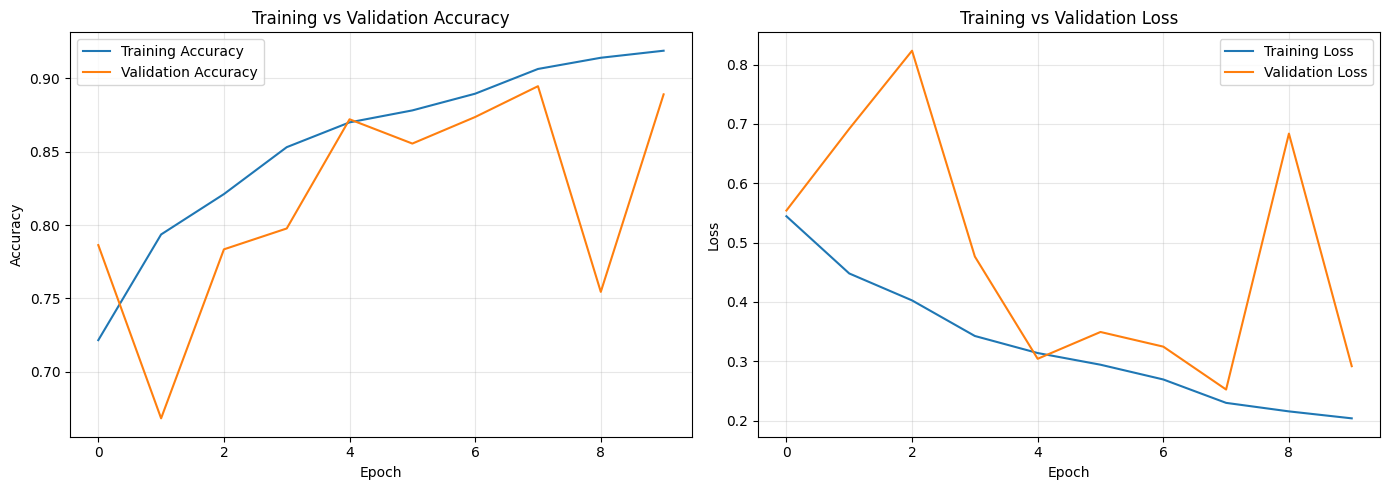

,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate
0,0.721453,0.799382,0.544520,0.930521,0.719463,0.786302,0.798490,0.554180,0.906255,0.829353,0.00100
1,0.793565,0.873118,0.448091,0.949705,0.794345,0.668112,0.878684,0.691811,0.979176,0.614810,0.00100
2,0.821100,0.899854,0.402673,0.958606,0.820763,0.783411,0.713813,0.823498,0.848736,0.900600,0.00100
3,0.853111,0.928382,0.342702,0.966761,0.853063,0.797643,0.918232,0.476605,0.973785,0.778119,0.00050
4,0.870032,0.940095,0.313983,0.969917,0.871055,0.872137,0.926139,0.304283,0.957462,0.885924,0.00050
5,0.878195,0.947486,0.294291,0.972023,0.879138,0.855570,0.932124,0.349448,0.969252,0.853769,0.00050
6,0.889595,0.955925,0.269416,0.974862,0.890476,0.873694,0.903789,0.324752,0.890842,0.966911,0.00050
7,0.906469,0.967822,0.229979,0.979722,0.906526,0.894708,0.954145,0.252484,0.971215,0.900334,0.00025
8,0.914108,0.971677,0.215632,0.981480,0.914180,0.754392,0.947130,0.683778,0.991447,0.711408,0.00025
9,0.918916,0.974482,0.203906,0.982712,0.918863,0.889148,0.947623,0.291799,0.968021,0.896598,0.00025


In [ ]:
history_df = pd.DataFrame(history.history)

# Save training history
HISTORY_PATH = (
    MODEL_DIR / "training_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

# Plot accuracy and loss
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    history_df["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)


axes[1].plot(
    history_df["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_df["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(history_df)

In [ ]:
training_config = {

    "experiment": "Model A - Custom CNN",

    "dataset": DATASET_ID,

    "dataset_revision": HF_REVISION,

    "target": "label_a",

    "class_mapping": {
        "0": "Real",
        "1": "AI-Generated"
    },

    "image_size": IMAGE_SIZE,

    "batch_size": BATCH_SIZE,

    "epochs_requested": EPOCHS,

    "epochs_completed": len(history.epoch),

    "optimizer": "Adam",

    "learning_rate": 0.001,

    "loss": "Binary Crossentropy",

    "class_weights": {
        str(k): float(v)
        for k, v in class_weights.items()
    },

    "seed": SEED,

    "training_samples": len(train_df),

    "validation_samples": len(val_df),

    "model": "custom_cnn_best.keras"
}

CONFIG_PATH = (
    MODEL_DIR / "custom_cnn_config.json"
)

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_config,
        f,
        indent=4
    )

print("Model and experiment configuration saved!")

for path in [
    BEST_MODEL_PATH,
    HISTORY_PATH,
    CONFIG_PATH
]:

    print(
        path.name,
        f"{path.stat().st_size / (1024**2):.2f} MB"
    )

Model and experiment configuration saved!
custom_cnn_best.keras 3.60 MB
training_history.csv 0.00 MB
custom_cnn_config.json 0.00 MB


In [ ]:
import base64
from google.colab import userdata

# Retrieve GitHub token from Colab Secrets
token = userdata.get("GITHUB_TOKEN")

if not token:
    raise ValueError("GITHUB_TOKEN is missing!")

# Files to upload
files_to_push = [
    BEST_MODEL_PATH,
    HISTORY_PATH,
    CONFIG_PATH
]

# Verify files and Git ignore status
for file_path in files_to_push:

    if not file_path.exists():
        raise FileNotFoundError(file_path)

    if file_path.stat().st_size >= 100 * 1024 * 1024:
        raise ValueError(
            f"{file_path.name} exceeds GitHub's "
            "100 MB single-file limit. Use Git LFS."
        )

    relative_path = str(
        file_path.relative_to(REPO_DIR)
    )

    ignored = subprocess.run(
        ["git", "check-ignore", "-q", relative_path],
        cwd=REPO_DIR
    )

    if ignored.returncode == 0:
        raise RuntimeError(
            f"{relative_path} is ignored by .gitignore"
        )

# Configure Git identity
subprocess.run(
    [
        "git", "config", "--local",
        "user.name", "Michael Andreas Tjendra"
    ],
    cwd=REPO_DIR,
    check=True
)

subprocess.run(
    [
        "git", "config", "--local",
        "user.email", "alongbest2000@gmail.com"
    ],
    cwd=REPO_DIR,
    check=True
)

# Stage model artifacts
subprocess.run(
    [
        "git", "add",
        "artifacts/models/custom_cnn_best.keras",
        "artifacts/models/training_history.csv",
        "artifacts/models/custom_cnn_config.json"
    ],
    cwd=REPO_DIR,
    check=True
)

# Commit staged files if there are changes
diff_result = subprocess.run(
    ["git", "diff", "--cached", "--quiet"],
    cwd=REPO_DIR
)

if diff_result.returncode != 0:

    subprocess.run(
        [
            "git", "commit",
            "-m", "Train and save Custom CNN model"
        ],
        cwd=REPO_DIR,
        check=True
    )

else:
    print("No new changes to commit.")

# Sync remote before pushing
subprocess.run(
    ["git", "fetch", "origin"],
    cwd=REPO_DIR,
    check=True
)

subprocess.run(
    ["git", "pull", "--rebase", "origin", "main"],
    cwd=REPO_DIR,
    check=True
)

# Temporary Git authentication
askpass_path = Path("/tmp/github-askpass.sh")

askpass_path.write_text("""#!/bin/sh
case "$1" in
    *sername*) printf '%s\\n' 'Michaelatj' ;;
    *assword*) printf '%s\\n' "$GITHUB_TOKEN" ;;
    *) exit 1 ;;
esac
""")

os.chmod(askpass_path, 0o700)

env = os.environ.copy()

env["GIT_ASKPASS"] = str(askpass_path)
env["GIT_TERMINAL_PROMPT"] = "0"
env["GITHUB_TOKEN"] = token

# Push
result = subprocess.run(
    ["git", "push", "origin", "main"],
    cwd=REPO_DIR,
    env=env,
    capture_output=True,
    text=True
)

if result.returncode != 0:

    print(result.stderr)

    raise RuntimeError(
        "GitHub push failed. Check repository synchronization."
    )

print(result.stdout)
print("Custom CNN artifacts successfully pushed!")


Custom CNN artifacts successfully pushed!


In [ ]:
subprocess.run(
    [
        "git",
        "status",
        "--short",
        "--branch"
    ],
    cwd=REPO_DIR,
    check=True
)

CompletedProcess(args=['git', 'status', '--short', '--branch'], returncode=0)